# Helsinki: door-to-door cost matrices per mode

First notebook for the paper *Does the carbon advantage of public transport and
cycling survive electrification?* Helsinki only, because cafein ships a
complete Helsinki data set (HSL GTFS with zone fares, OSM, 10 m DEM, HSY
population grid).

This notebook produces the raw material every indicator is computed from:
one origin-destination matrix per mode, each with **time**, **money** and
**life-cycle CO₂e** columns, on a shared H3 origin lattice.

| Step | Output |
|---|---|
| 1. Origin lattice | H3 resolution 8 hexagons with population (`lattice.gpkg`) |
| 2. Street network | `networks/helsinki-streets.cafein` (walk, bicycle, car, with DEM) |
| 3. Street matrices | `car/` and `bicycle/` Parquet directories |
| 4. Transit matrices | `transit/` (shipped fleet) and `transit-bus-bev/` |
| 5. Resident table | One long Parquet with time, money, emissions per mode |

The indicators (carbon gap, time and money sacrifice per kg, choice classes)
live in the next notebook; this one stops at the matrices.

**Compute note.** Steps 2 to 4 are heavy. Every matrix is streamed to Parquet
with `resume=True`, so the notebook can be re-run and skips finished work.
Run it through the batch script `jobs/helsinki-od-matrices.sbatch`, or in an
interactive session with more than the two cores an OnDemand desktop gets.

In [1]:
import json
import time
from pathlib import Path

import geopandas as gpd
import h3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cafein
import cafein.sampledata.helsinki as helsinki
from cafein import StreetNetwork, TransportNetwork, TravelCostMatrix
from cafein.emissions import default_factors, vehicle_class_factors
from cafein.fares import zone_fare_structure

print("cafein", cafein.__version__)

cafein 0.31.0


## Parameters

Everything that could differ between cities is collected here so that the same
notebook can later be pointed at another recipe. Values are also written to
`parameters.json` next to the outputs as provenance.

In [2]:
CITY = "helsinki"

# Artifacts shared with the tutorial notebooks live next to this notebook.
ARTIFACTS = Path("networks")
TRANSIT_ARTIFACT = ARTIFACTS / "helsinki-region.cafein"
STREET_ARTIFACT = ARTIFACTS / "helsinki-streets.cafein"

# Large intermediate results go to scratch (auto-cleaned after 180 days of
# no use; keep what matters in projappl or Allas when the analysis settles).
RESULTS = Path("/scratch/project_2010423/carbon-advantage") / CITY
RESULTS.mkdir(parents=True, exist_ok=True)

PARAMETERS = {
    "city": CITY,
    "cafein_version": cafein.__version__,
    "h3_resolution": 8,
    # Tuesday inside the feed's validity window (2026-08-20 to 2026-10-18).
    "departure": "2026-09-08 08:30",
    # The centre used for the ring profiles: Helsinki central railway station.
    "centre_lat_lon": (60.1719, 24.9414),
    # Street routing.
    "car_profile": "rush",          # intersection-delay model
    "car_parking": True,            # shipped constant: 300 s, 0 m
    "car_vehicle_class": "ICE",     # baseline; scenarios rescale per km
    "max_street_time_min": 120,
    # Riding speeds of the cycling modes in km/h, passed to every street query.
    # cafein's defaults since 0.30: the mean trip speeds of conventional
    # bicycles and pedelecs in Schleinitz et al. (2017). The bicycle is also
    # slowed uphill and credited downhill by the slope model; the e-bike is not.
    "street_speeds_kmph": {"bicycle": 15.3, "e_bike": 17.4},
    # Transit routing.
    "max_rides": 8,
    "fare_rules": "zones",          # HSL zone tickets A to E
    "output_time_units": "seconds",
    # A ferry row is missing from the shipped defaults; HSL's Suomenlinna
    # ferry is route_type 4. Placeholder until the full row set ships.
    "ferry_factor_g_per_pkm": {
        "vehicle": 5.0, "fuel": 100.0, "infrastructure": 5.0, "operations": 5.0
    },
}

(RESULTS / "parameters.json").write_text(json.dumps(PARAMETERS, indent=2))
RESULTS

PosixPath('/scratch/project_2010423/carbon-advantage/helsinki')

## 1. Origin lattice

Every inhabited cell of the city on one H3 resolution 8 lattice (about
0.74 km² per hexagon). Population comes from HSY's 250 m grid by area-weighted
overlay. Destinations are the same lattice: the primary, POI-free destination
layer is population within reach.

cafein's `zones.h3_grid` targets the h3 v4 API, while this environment has
h3 3.7; the helper below follows the same `cafein.zones` protocol
(`id`, `centroid_lat`, `centroid_lon`, `geometry` in EPSG:4326) with either
API.

In [3]:
def h3_cells_covering(polygons, resolution):
    '''H3 cells covering a polygon layer, in the cafein.zones protocol.'''
    polygons = polygons.to_crs(4326)
    ids = set()
    for geometry in polygons.geometry:
        if geometry is None or geometry.is_empty:
            continue
        for polygon in getattr(geometry, "geoms", [geometry]):
            if hasattr(h3, "polyfill"):  # h3 v3
                ids |= h3.polyfill(
                    polygon.__geo_interface__, resolution, geo_json_conformant=True
                )
                ids.add(h3.geo_to_h3(polygon.centroid.y, polygon.centroid.x, resolution))
            else:  # h3 v4
                ids |= set(h3.geo_to_cells(polygon, resolution))
                ids.add(h3.latlng_to_cell(polygon.centroid.y, polygon.centroid.x, resolution))
    ids = sorted(ids)
    if hasattr(h3, "h3_to_geo_boundary"):  # h3 v3
        centres = [h3.h3_to_geo(i) for i in ids]
        rings = [h3.h3_to_geo_boundary(i, geo_json=True) for i in ids]
    else:
        centres = [h3.cell_to_latlng(i) for i in ids]
        rings = [tuple((lng, lat) for lat, lng in h3.cell_to_boundary(i)) for i in ids]
    from shapely.geometry import Polygon

    return gpd.GeoDataFrame(
        {
            "id": ids,
            "centroid_lat": [c[0] for c in centres],
            "centroid_lon": [c[1] for c in centres],
        },
        geometry=[Polygon(r) for r in rings],
        crs="EPSG:4326",
    )


population_grid = gpd.read_file(helsinki.population_grid)
population_grid = population_grid.rename(columns={"asukkaita": "population"})
population_grid = population_grid.loc[population_grid["population"] > 0, ["population", "geometry"]]

lattice = h3_cells_covering(population_grid, PARAMETERS["h3_resolution"])
print(f"{len(population_grid):,} inhabited 250 m cells -> {len(lattice):,} H3 cells")

5,825 inhabited 250 m cells -> 1,105 H3 cells


In [4]:
# Area-weighted transfer of population onto the hexagons (metric CRS).
metric_crs = population_grid.crs
squares = population_grid.copy()
squares["square_area"] = squares.geometry.area
pieces = gpd.overlay(
    squares,
    lattice.to_crs(metric_crs)[["id", "geometry"]],
    how="intersection",
)
pieces["population"] = pieces["population"] * pieces.geometry.area / pieces["square_area"]
hex_population = pieces.groupby("id")["population"].sum()

lattice["population"] = lattice["id"].map(hex_population).fillna(0.0)
lattice = lattice.loc[lattice["population"] > 0].reset_index(drop=True)

# Distance to the centre for the ring profiles.
centre = gpd.GeoSeries(
    gpd.points_from_xy([PARAMETERS["centre_lat_lon"][1]], [PARAMETERS["centre_lat_lon"][0]]),
    crs="EPSG:4326",
).to_crs(metric_crs).iloc[0]
lattice["centre_km"] = lattice.to_crs(metric_crs).geometry.centroid.distance(centre) / 1000

print(f"{len(lattice):,} inhabited hexagons, population {lattice['population'].sum():,.0f}")
lattice.to_file(RESULTS / "lattice.gpkg", driver="GPKG")
lattice.head()

1,105 inhabited hexagons, population 1,251,940


,id,centroid_lat,centroid_lon,geometry,population,centre_km
0,8808996049fffff,60.306037,24.532448,"POLYGON ((24.52487 60.30468, 24.5305 60.30163,...",4.086427,27.134520
1,8808996065fffff,60.280252,24.569880,"POLYGON ((24.5623 60.2789, 24.56793 60.27584, ...",5.882244,23.862294
2,880899606dfffff,60.281949,24.556681,"POLYGON ((24.54911 60.28059, 24.55473 60.27754...",2.909169,24.589263
3,8808996083fffff,60.352865,24.658065,"POLYGON ((24.65046 60.35151, 24.6561 60.34845,...",54.490176,25.539151
4,8808996085fffff,60.339628,24.652156,"POLYGON ((24.64456 60.33827, 24.65019 60.33522...",5.000000,24.605797


In [5]:
lattice.explore()

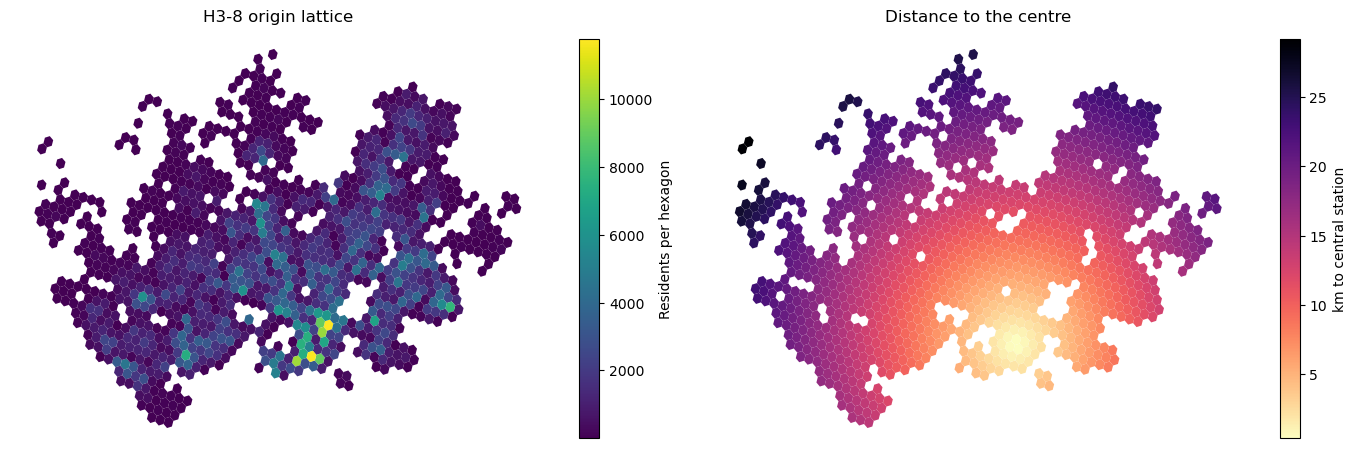

In [6]:
figure, axes = plt.subplots(ncols=2, figsize=(14, 6))
lattice.to_crs(metric_crs).plot(
    ax=axes[0], column="population", cmap="viridis", legend=True, linewidth=0,
    legend_kwds={"label": "Residents per hexagon", "shrink": 0.7},
)
axes[0].set_title("H3-8 origin lattice")
lattice.to_crs(metric_crs).plot(
    ax=axes[1], column="centre_km", cmap="magma_r", legend=True, linewidth=0,
    legend_kwds={"label": "km to central station", "shrink": 0.7},
)
axes[1].set_title("Distance to the centre")
for axis in axes:
    axis.set_axis_off()
figure.tight_layout()

## 2. Street network artifact

The transit artifact built in the tutorial carries a multimodal street graph
for access and egress, but standalone car and bicycle matrices need a
`StreetNetwork`. Build it once with the DEM (slope-aware profiles) and the
Finnish legal speed limits, then reuse the saved artifact.

In [7]:
if STREET_ARTIFACT.exists():
    streets = StreetNetwork.load(STREET_ARTIFACT)
    print("loaded", STREET_ARTIFACT)
else:
    started = time.time()
    streets = StreetNetwork.from_osm(
        helsinki.osm_pbf,
        modes=("walk", "bicycle", "car"),
        dem=helsinki.dem,
        dem_interval=25,
        country="FI",
    )
    streets.save(STREET_ARTIFACT)
    print(f"built and saved in {time.time() - started:.0f} s")

print(f"vertices {streets.vertex_count:,}, edges {streets.edge_count:,}")
streets.elevation_metadata

reading the OSM street network:   0%|          | 0/100 [00:02<?, ?it/s]

built and saved in 21 s
vertices 1,474,309, edges 1,644,890


{'source': '/scratch/project_2010423/cafein-sampledata/helsinki/helsinki-2026.08.4/b4a7e60a914279c1ba005ea0a03f0352c0be7fc342f73df86d78d35efbacf6d5/helsinki_dem_10m.tif',
 'sampling_interval': 25.0,
 'nodata_policy': 'nan',
 'coverage': 0.9991899608517468,
 'inferred_edges': 5422}

## 3. Street matrices: car, bicycle, e-bike and walk

One matrix per street mode over the lattice, with:

- `travel_time` in seconds (car: rush-hour intersection delays plus the
  parking search at the destination),
- `emissions` in g CO₂e over the ridden network metres at the shipped
  life-cycle factor (car at occupancy 1 and ICE; the fleet scenarios are
  linear in `network_distance_m`, so they are derived later without
  re-routing),
- `cost_private` in EUR2017 per the Gössling et al. (2019) vehicle-operation
  bundle, the car's marginal cost (no ownership).

The e-bike rides the bicycle permissions with the `e_bike` profile: 17.4 km/h
against the bicycle's 15.3 km/h on the flat (the mean trip speeds of pedelecs
and conventional bicycles in Schleinitz et al. 2017, cafein's defaults since
0.30, set explicitly in `street_speeds_kmph`), no slope effect (the bicycle is
slowed uphill and credited downhill, the e-bike is not), its own life-cycle
factor (25 g CO₂e per km against the bicycle's 37) and the bicycle's running
cost, as cafein ships no e-bike cost row.

Streamed to a Parquet directory. A directory whose manifest shows every shard completed is skipped; a partial one is resumed. The manifest fingerprint ties a resume to the exact query, so a changed parameter needs a fresh output directory.

In [8]:
def matrix_complete(path):
    '''True when a streamed matrix directory has every shard completed.'''
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


def read_matrix(path):
    '''A completed streamed matrix directory as one DataFrame, shards verified.'''
    from cafein._streaming import read_shards

    return read_shards(path)


STREET_MODES = {
    "car": dict(
        intersection_delays=True,
        profile=PARAMETERS["car_profile"],
        parking=PARAMETERS["car_parking"],
        vehicle_class=PARAMETERS["car_vehicle_class"],
        occupancy=1,
    ),
    "bicycle": dict(speeds={"bicycle": PARAMETERS["street_speeds_kmph"]["bicycle"]}),
    "e_bike": dict(speeds={"e_bike": PARAMETERS["street_speeds_kmph"]["e_bike"]}),
    "walk": {},
}

street_results = {}
for mode, options in STREET_MODES.items():
    output = RESULTS / mode
    if matrix_complete(output):
        print(f"{mode:8} complete -> {output}")
        continue
    started = time.time()
    street_results[mode] = TravelCostMatrix.to_parquet(
        streets,
        lattice,
        lattice,
        transport_mode=mode,
        max_street_time=PARAMETERS["max_street_time_min"],
        perspectives="private",
        output_time_units=PARAMETERS["output_time_units"],
        output=output,
        resume=output.exists(),  # a first run has nothing to resume
        **options,
    )
    print(f"{mode:8} {time.time() - started:7.0f} s -> {output}")

street matrix:  30%|###       | 150/500 [00:02<00:04, 74.84it/s]

street matrix:  30%|###       | 150/500 [00:02<00:04, 74.85it/s]

car           12 s -> /scratch/project_2010423/carbon-advantage/helsinki/car


street matrix:  30%|###       | 150/500 [00:02<00:04, 74.85it/s]

street matrix:  25%|##5       | 125/500 [00:02<00:06, 62.38it/s]

bicycle       14 s -> /scratch/project_2010423/carbon-advantage/helsinki/bicycle


street matrix:  20%|##        | 100/500 [00:02<00:08, 49.89it/s]

street matrix:  25%|##5       | 125/500 [00:02<00:06, 62.38it/s]

e_bike        14 s -> /scratch/project_2010423/carbon-advantage/helsinki/e_bike


walk           1 s -> /scratch/project_2010423/carbon-advantage/helsinki/walk


In [9]:
car = read_matrix(RESULTS / "car")
print(f"car: {len(car):,} reachable pairs of {len(lattice) ** 2:,}")
car.describe().T

car: 1,190,301 reachable pairs of 1,221,025


,count,mean,std,min,25%,50%,75%,max
travel_time,1190301.0,2733.217038,826.334154,300.0,2144.000000,2696.000000,3288.000000,7051.000000
distance_m,1190301.0,22981.114064,10413.481483,0.0,15172.795252,22509.043598,30333.822282,61262.226724
network_distance_m,1190301.0,22850.450907,10402.104163,0.0,15053.600574,22380.468305,30194.869994,61103.181000
connector_distance_m,1190301.0,130.663157,110.822307,0.0,46.412238,97.724366,186.956713,956.263883
emissions,1190301.0,3701.773047,1685.140874,0.0,2438.683293,3625.635865,4891.568939,9898.715322
cost_private,1190301.0,5.712613,2.600526,0.0,3.763400,5.595117,7.548717,15.275795


### E-bike against bicycle

The e-bike is faster on the flat (17.4 against 15.3 km/h) and keeps its speed
on slopes, so the time ratio reflects the speed gap, the bicycle's slope model
and the route choice it induces. The table records how far apart the two modes
are on the shared pairs, as the record of the speed assumption behind the
e-bike results.

In [10]:
bicycle = read_matrix(RESULTS / "bicycle")
e_bike = read_matrix(RESULTS / "e_bike")
pair = bicycle.merge(e_bike, on=["from_id", "to_id"], suffixes=("_bicycle", "_e_bike"))
ratio = pair["travel_time_e_bike"] / pair["travel_time_bicycle"]
comparison = pd.DataFrame({
    mode: {
        "pairs": len(frame),
        "median_speed_kmh": (pair[f"network_distance_m_{mode}"] / pair[f"travel_time_{mode}"] * 3.6).median(),
        "median_g_per_km": (pair[f"emissions_{mode}"] / pair[f"network_distance_m_{mode}"] * 1000).median(),
        "median_eur_per_km": (pair[f"cost_private_{mode}"] / pair[f"network_distance_m_{mode}"] * 1000).median(),
    }
    for mode, frame in [("bicycle", bicycle), ("e_bike", e_bike)]
})
print(f"{len(pair):,} shared pairs; e-bike over bicycle time ratio: median {ratio.median():.3f}, "
      f"5th to 95th percentile {ratio.quantile(0.05):.3f} to {ratio.quantile(0.95):.3f}; "
      f"same route on {(pair['network_distance_m_bicycle'] == pair['network_distance_m_e_bike']).mean():.0%} of pairs")
comparison.round(3)


1,058,538 shared pairs; e-bike over bicycle time ratio: median 0.872, 5th to 95th percentile 0.869 to 0.881; same route on 61% of pairs


,bicycle,e_bike
pairs,1058538.000,1135950.000
median_speed_kmh,14.879,17.069
median_g_per_km,37.000,25.000
median_eur_per_km,0.047,0.047


## 4. Transit matrices

Door-to-door public transport at the common departure, with the HSL zone
tickets priced exactly (`money`, EUR) and life-cycle emissions over the ridden
legs. Two runs with identical routing and different factor tables give the
*today* and *electric buses* fleet states; only `emissions` differs between
them.

The shipped defaults cover route types 0 to 3 and their extended codes
(HSL uses 701/702/704 for buses, 109 for trains, 900 for trams). Ferries
(route type 4) have no row yet, so a placeholder row is layered on until the
complete default set ships.

In [11]:
network = TransportNetwork.load(TRANSIT_ARTIFACT)
fares = zone_fare_structure(helsinki.gtfs, rules=PARAMETERS["fare_rules"])

ferry_row = {"route_type": 4, **PARAMETERS["ferry_factor_g_per_pkm"]}
factors_today = pd.DataFrame([ferry_row])

electric_bus = vehicle_class_factors().loc["bus-BEV"].to_dict()
electric_bus["route_type"] = 3
factors_bus_bev = pd.DataFrame([ferry_row, electric_bus])

TRANSIT_RUNS = {
    "transit": factors_today,
    "transit-bus-bev": factors_bus_bev,
}
factors_bus_bev

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

,route_type,vehicle,fuel,infrastructure,operations
0,4,5.0,100.0,5.0,5.0
1,3,14.0,10.0,4.0,1.0


In [12]:
transit_results = {}
for label, factors in TRANSIT_RUNS.items():
    output = RESULTS / label
    if matrix_complete(output):
        print(f"{label:16} complete -> {output}")
        continue
    started = time.time()
    transit_results[label] = TravelCostMatrix.to_parquet(
        network,
        lattice,
        lattice,
        PARAMETERS["departure"],
        max_rides=PARAMETERS["max_rides"],
        factors=factors,
        fares=fares,
        output_time_units=PARAMETERS["output_time_units"],
        output=output,
        resume=output.exists(),  # a first run has nothing to resume
    )
    print(f"{label:16} {time.time() - started:7.0f} s -> {output}")

transit               10 s -> /scratch/project_2010423/carbon-advantage/helsinki/transit


transit-bus-bev       13 s -> /scratch/project_2010423/carbon-advantage/helsinki/transit-bus-bev


In [13]:
transit = read_matrix(RESULTS / "transit")
print(f"transit: {len(transit):,} reachable pairs")
print("unpriced fares:", transit["money"].isna().sum(), "| unresolved emissions:", transit["emissions"].isna().sum())
transit.describe().T

transit: 1,212,205 reachable pairs
unpriced fares: 50 | unresolved emissions: 0


,count,mean,std,min,25%,50%,75%,max
travel_time,1212205.0,5083.168018,1975.593259,0.0,3654.000000,4829.000000,6253.000000,15669.000000
transfers,1212205.0,1.825291,1.032317,0.0,1.000000,2.000000,2.000000,7.000000
transit_distance_m,1212205.0,23363.343165,12228.807151,0.0,14083.000000,22254.000000,31559.000000,90092.000000
walk_distance_m,1212205.0,2084.124005,1123.616180,0.0,1309.759883,1814.458773,2567.197187,12888.322489
emissions,1212205.0,1493.628577,827.151171,0.0,873.394000,1384.753000,2014.800000,6068.688000
money,1212155.0,3.616718,0.677696,0.0,3.300000,3.300000,4.500000,8.300000


## 5. Resident table

One long table with the three resident-side quantities per mode and OD pair.
Time is the door-to-door duration in seconds, money the per-trip marginal cost
in EUR, emissions in g CO₂e. The fleet scenarios are not expanded here: the
car, bicycle and e-bike rows keep their distance so the factor ladder can be applied
in the indicators notebook, and the electric-bus transit run is stored as its
own mode label.

In [14]:
def resident_rows(frame, mode, time_col="travel_time", money_col=None, distance_col=None):
    rows = pd.DataFrame({
        "from_id": frame["from_id"].astype(str),
        "to_id": frame["to_id"].astype(str),
        "mode": mode,
        "time_s": frame[time_col].astype(float),
        "money": frame[money_col].astype(float) if money_col else np.nan,
        "emissions_g": frame["emissions"].astype(float),
        "distance_m": frame[distance_col].astype(float) if distance_col else np.nan,
    })
    return rows


resident = pd.concat(
    [
        resident_rows(car, "car", money_col="cost_private", distance_col="network_distance_m"),
        resident_rows(read_matrix(RESULTS / "bicycle"), "bicycle", money_col="cost_private", distance_col="network_distance_m"),
        resident_rows(read_matrix(RESULTS / "e_bike"), "e_bike", money_col="cost_private", distance_col="network_distance_m"),
        resident_rows(transit, "transit", money_col="money", distance_col="transit_distance_m"),
        resident_rows(read_matrix(RESULTS / "transit-bus-bev"), "transit-bus-bev", money_col="money", distance_col="transit_distance_m"),
    ],
    ignore_index=True,
)
resident["mode"] = resident["mode"].astype("category")
resident.to_parquet(RESULTS / "resident_table.parquet", index=False)
resident.groupby("mode", observed=True).agg(
    pairs=("time_s", "size"),
    time_min_median=("time_s", lambda s: s.median() / 60),
    money_median=("money", "median"),
    emissions_median=("emissions_g", "median"),
)

,pairs,time_min_median,money_median,emissions_median
mode,,,,
bicycle,1058538,65.150000,0.755506,594.760163
car,1190301,44.933333,5.595117,3625.635865
e_bike,1135950,59.550000,0.792145,421.353673
transit,1212205,80.483333,3.300000,1384.753000
transit-bus-bev,1212205,80.483333,3.300000,616.156000


### First look: distributions per mode

Population-unweighted, all reachable pairs. Enough to sanity-check the
magnitudes before building the indicators.

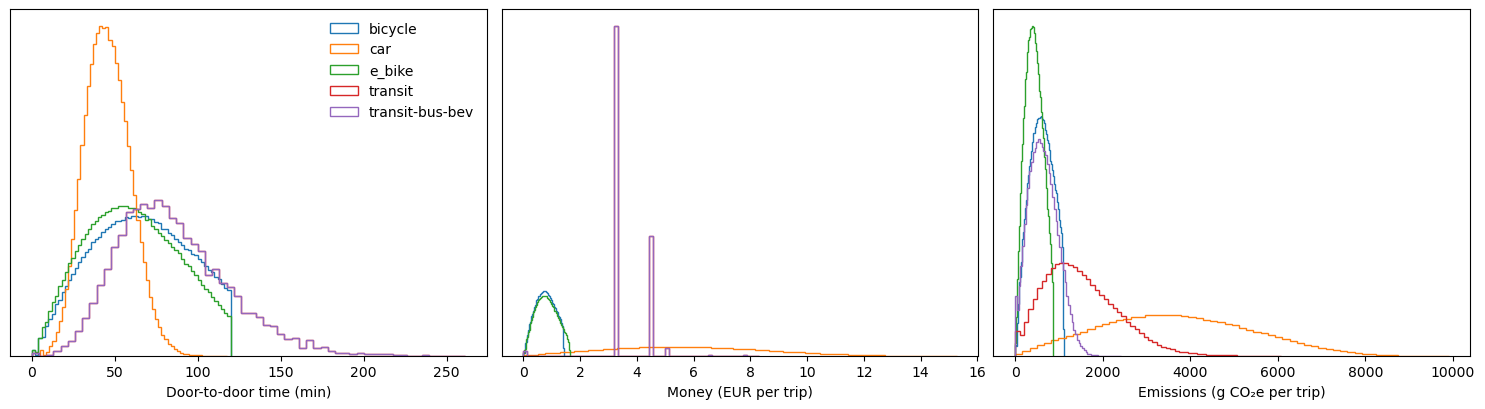

In [15]:
figure, axes = plt.subplots(ncols=3, figsize=(15, 4.2))
columns = [("time_s", "Door-to-door time (min)", 1 / 60), ("money", "Money (EUR per trip)", 1), ("emissions_g", "Emissions (g CO₂e per trip)", 1)]
for axis, (column, label, scale) in zip(axes, columns):
    for mode, group in resident.groupby("mode", observed=True):
        values = group[column].dropna() * scale
        if values.empty:
            continue
        axis.hist(values, bins=60, histtype="step", density=True, label=mode)
    axis.set_xlabel(label)
    axis.set_yticks([])
axes[0].legend(frameon=False)
figure.tight_layout()

## Next

- `02.2`: decay weights w(o,d) shared with the accessibility measure, carbon
  gap, time and money sacrifice per kg, choice classes, ring profiles.
- Open points carried from this notebook: a proper ferry factor row; the
  departure window (one departure now, a window with a median later); the
  pass-prorated fare lower bound beside the single ticket; the
  `cafein.lca` grid rescaling once that module is available in the installed
  version.